# Visualize Diagnostics Across Layers

This Visualize notebook loads the cached data produced by `Generate-fiedler-values-across-layers.ipynb`, `Generate-HFER-across-layers.ipynb`, and `Generate-spectral-entropy-across-layers.ipynb`. It compares layer-specific graph-spectral diagnostics across all 28 layers at a fixed context length of $N = 2000$ tokens for the main numerical input families using Llama-3.2-3B, providing the across-layer comparison presented under **Robustness and Layerwise Consistency of Graph-Spectral Diagnostics** in the appendix. Shaded bands show standard deviations across realizations.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.transforms import Bbox
from matplotlib.ticker import FormatStrFormatter

In [2]:
CACHE_DIR = Path("cache")

DATA_FILES = {
    "fiedler": CACHE_DIR / "fiedler_per_layer.npz",
    "hfer": CACHE_DIR / "hfer_per_layer.npz",
    "effective_modes": CACHE_DIR / "spectral_entropy_per_layer.npz",
}

REQUIRED_KEYS = {
    "fiedler": ["input_names", "layer_numbers", "fiedler_mean", "fiedler_std"],
    "hfer": ["input_names", "layer_numbers", "hfer_mean", "hfer_std"],
    "effective_modes": [
        "input_names",
        "layer_numbers",
        "effective_modes_mean",
        "effective_modes_std",
    ],
}

EXPECTED_INPUT_NAMES = np.asarray([
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
], dtype=str)
EXPECTED_LAYER_NUMBERS = np.arange(1, 29, dtype=int)


def _load_metric_cache(metric_name):
    path = DATA_FILES[metric_name]
    if not path.exists():
        raise FileNotFoundError(f"Expected relative cache path {path} to exist before plotting.")

    required_keys = REQUIRED_KEYS[metric_name]
    with np.load(path, allow_pickle=False) as data:
        missing_keys = [key for key in required_keys if key not in data.files]
        if missing_keys:
            raise KeyError(f"Missing required keys in {path}: {missing_keys}")
        return {key: data[key] for key in required_keys}


# Load and validate cached plotting data
fiedler_cache = _load_metric_cache("fiedler")
hfer_cache = _load_metric_cache("hfer")
effective_modes_cache = _load_metric_cache("effective_modes")

input_names = fiedler_cache["input_names"].astype(str)
layer_numbers = fiedler_cache["layer_numbers"].astype(int)

if not np.array_equal(input_names, EXPECTED_INPUT_NAMES):
    raise ValueError(f"Unexpected input_names order: {input_names.tolist()}")
if not np.array_equal(layer_numbers, EXPECTED_LAYER_NUMBERS):
    raise ValueError(f"Expected layer_numbers == 1..28, got {layer_numbers.tolist()}.")

for cache_name, cache in {
    "hfer": hfer_cache,
    "effective_modes": effective_modes_cache,
}.items():
    if not np.array_equal(cache["input_names"].astype(str), input_names):
        raise ValueError(f"{cache_name} input_names do not match the Fiedler cache.")
    if not np.array_equal(cache["layer_numbers"].astype(int), layer_numbers):
        raise ValueError(f"{cache_name} layer_numbers do not match the Fiedler cache.")

fiedler_mean = fiedler_cache["fiedler_mean"].astype(float)
fiedler_std = fiedler_cache["fiedler_std"].astype(float)
hfer_mean = hfer_cache["hfer_mean"].astype(float)
hfer_std = hfer_cache["hfer_std"].astype(float)
effective_modes_mean = effective_modes_cache["effective_modes_mean"].astype(float)
effective_modes_std = effective_modes_cache["effective_modes_std"].astype(float)

expected_summary_shape = (len(input_names), len(layer_numbers))
for array_name, array_value in {
    "fiedler_mean": fiedler_mean,
    "fiedler_std": fiedler_std,
    "hfer_mean": hfer_mean,
    "hfer_std": hfer_std,
    "effective_modes_mean": effective_modes_mean,
    "effective_modes_std": effective_modes_std,
}.items():
    if array_value.shape != expected_summary_shape:
        raise ValueError(
            f"{array_name} has shape {array_value.shape}, expected {expected_summary_shape}."
        )

In [3]:
def _diagnostic_line_style(data_name):
    # Use one visual encoding consistently across all diagnostic panels.
    if data_name in {"Constant 500", "Constant sampled"}:
        style = dict(color="#D8D7E6", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.2":
        style = dict(color="#C6D9F1", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5":
        style = dict(color="#A9C8EA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.55":
        style = dict(color="#83B2DC", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.566":
        style = dict(color="#5F98CA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5692":
        style = dict(color="#3E78B2", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.5698":
        style = dict(color="#24518A", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.9":
        style = dict(color="#E68169", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Logistic r=4.0":
        style = dict(color="#C8525E", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Lorenz":
        style = dict(color="#98334F", linestyle="-.", marker="o", linewidth=2.8)
    else:
        style = dict(color="#4C72B0", linestyle="-", marker="o", linewidth=2.0)

    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2

    style["markersize"] = 4.0
    return style

Saved figures/per_layer_combined_diagnostics.pdf


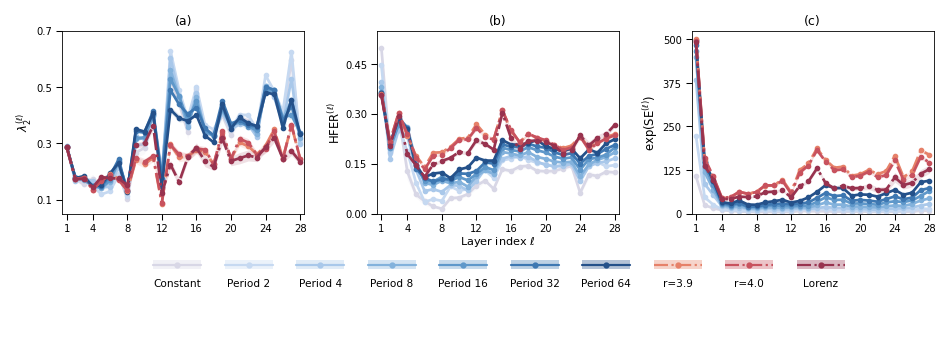

In [4]:
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
COMBINED_FIGURE_PATH = FIGURE_DIR / "per_layer_combined_diagnostics.pdf"

x = layer_numbers.astype(float)


def _plot_layer_diagnostic(ax, mean, std):
    for input_idx, data_name in enumerate(input_names):
        y = mean[input_idx].astype(float)
        band = std[input_idx].astype(float)
        style = _diagnostic_line_style(str(data_name))
        zorder = style.get("zorder", 2)
        ax.plot(
            x,
            y,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.3,
            marker=style["marker"],
            markersize=1.7,
            zorder=zorder,
        )
        ax.fill_between(
            x,
            y - band,
            y + band,
            color=style["color"],
            alpha=0.15,
            linewidth=0,
            zorder=max(zorder - 0.5, 0),
        )


def _format_combined_axis(ax, ylabel):
    ax.set_ylabel(ylabel, labelpad=1, fontsize=5.6)
    ax.set_xlim(0.5, int(layer_numbers[-1]) + 0.5)
    ax.set_xticks([1, 4, 8, 12, 16, 20, 24, 28])
    ax.xaxis.set_major_formatter(FormatStrFormatter("%d"))
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)


complexity_legend_order = [
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
]


def _complexity_legend_rows(data_name):
    label_map = {
        "Constant sampled": ("Constant", ""),
        "Logistic r=3.2": ("Period 2", ""),
        "Logistic r=3.5": ("Period 4", ""),
        "Logistic r=3.55": ("Period 8", ""),
        "Logistic r=3.566": ("Period 16", ""),
        "Logistic r=3.5692": ("Period 32", ""),
        "Logistic r=3.5698": ("Period 64", ""),
        "Logistic r=3.9": ("r=3.9", ""),
        "Logistic r=4.0": ("r=4.0", ""),
        "Lorenz": ("Lorenz", ""),
    }
    return label_map.get(str(data_name), (str(data_name), ""))


def _add_complexity_strip_legend(fig):
    ordered_names = [name for name in complexity_legend_order if name in set(input_names.astype(str))]
    ax_leg = fig.add_axes([0.075, 0.130, 0.910, 0.185])
    ax_leg.set_xlim(-0.55, len(ordered_names) - 0.45)
    ax_leg.set_ylim(0.0, 1.0)
    ax_leg.axis("off")

    spacing_scale = 0.84
    swatch_half_width = 0.28
    swatch_height = 0.115
    legend_center = 0.5 * (len(ordered_names) - 1)

    def _legend_x(raw_x):
        return legend_center + spacing_scale * (float(raw_x) - legend_center)

    for idx, data_name in enumerate(ordered_names):
        legend_x = _legend_x(idx)
        style = _diagnostic_line_style(str(data_name))
        ax_leg.add_patch(
            Rectangle(
                (legend_x - swatch_half_width, 0.7850),
                2.0 * swatch_half_width,
                swatch_height,
                facecolor=style["color"],
                edgecolor="none",
                alpha=0.34,
            )
        )
        ax_leg.plot(
            [legend_x - swatch_half_width, legend_x + swatch_half_width],
            [0.8425, 0.8425],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.05,
            solid_capstyle="round",
        )
        ax_leg.plot(legend_x, 0.8425, marker=style["marker"], markersize=2.0, color=style["color"])
        top_label, bottom_label = _complexity_legend_rows(data_name)
        ax_leg.text(legend_x, 0.605, top_label, ha="center", va="center", fontsize=5.06)
        if bottom_label:
            ax_leg.text(legend_x, 0.505, bottom_label, ha="center", va="center", fontsize=5.06)


with plt.rc_context({
    "font.size": 7.6,
    "axes.labelsize": 5.4,
    "axes.titlesize": 6.0,
    "xtick.labelsize": 4.8,
    "ytick.labelsize": 4.8,
    "legend.fontsize": 8.74,
    "axes.linewidth": 0.4,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig = plt.figure(figsize=(6.30, 2.87), dpi=150)
    gs = fig.add_gridspec(
        1,
        3,
        left=0.068,
        right=0.990,
        top=0.830,
        bottom=0.405,
        wspace=0.30,
    )

    ax_fiedler = fig.add_subplot(gs[0, 0])
    ax_hfer = fig.add_subplot(gs[0, 1])
    ax_active = fig.add_subplot(gs[0, 2])

    _plot_layer_diagnostic(ax_fiedler, fiedler_mean, fiedler_std)
    _plot_layer_diagnostic(ax_hfer, hfer_mean, hfer_std)
    _plot_layer_diagnostic(ax_active, effective_modes_mean, effective_modes_std)

    _format_combined_axis(ax_fiedler, r"$\lambda_2^{(\ell)}$")
    _format_combined_axis(ax_hfer, r"$\mathrm{HFER}^{(\ell)}$")
    _format_combined_axis(ax_active, r"$\exp(\mathrm{SE}^{(\ell)})$")

    ax_fiedler.set_ylim(0.05, 0.70)
    ax_fiedler.set_yticks([0.1, 0.3, 0.5, 0.7])
    ax_fiedler.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax_hfer.set_ylim(0.0, 0.55)
    ax_hfer.set_yticks([0.00, 0.15, 0.30, 0.45])
    ax_hfer.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax_active.set_ylim(0.0, 525.0)
    ax_active.set_yticks([0, 125, 250, 375, 500])
    for ax in (ax_fiedler, ax_hfer, ax_active):
        ax.tick_params(axis="both", which="major", length=2.8, pad=2.0)
    for panel_label, ax in zip(["(a)", "(b)", "(c)"], [ax_fiedler, ax_hfer, ax_active]):
        ax.set_title(panel_label, pad=3.0)

    _add_complexity_strip_legend(fig)
    middle_axis_center = ax_hfer.get_position().x0 + 0.5 * ax_hfer.get_position().width
    fig.supxlabel(r"Layer index $\ell$", x=middle_axis_center, y=0.325, fontsize=5.4)
    fig.align_ylabels([ax_fiedler, ax_hfer, ax_active])
    fig.canvas.draw()
    tight_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.02)
    pdf_bbox = Bbox.from_extents(
        tight_bbox.x0,
        tight_bbox.y0 + 0.30,
        tight_bbox.x1,
        tight_bbox.y1,
    )
    fig.savefig(COMBINED_FIGURE_PATH, format="pdf", bbox_inches=pdf_bbox)
    print(f"Saved {COMBINED_FIGURE_PATH}")
    plt.show()